In [1]:
%pylab inline
import smatch
from astropy.table import Table, vstack
import pltutil
import astropy.io.ascii as ascii

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd wrkDir/

/work/xiangchong.li/work/galSim-HSC


In [114]:
# Initialization
cmpDir  =   'database/compare/'
catname6=   os.path.join(cmpDir,'scat-%s.fits' %'s16') # in S16a FDFC region
catname8=   os.path.join(cmpDir,'scat-%s.fits' %'s18')
catname9=   os.path.join(cmpDir,'scat-%s.fits' %'s19')
matname =   os.path.join(cmpDir,'match-s16-s19.fits')
pltDir  =   os.path.join(cmpDir,'plot','magDiff')

In [4]:
if not os.path.isfile(matname):
    print('regenerating matched catalog')
    # Read catalogs
    data16  =   Table.read(catname6);print('number of gals in S16A: %d' %len(data16))
    data19  =   Table.read(catname9);print('number of gals in S19A: %d' %len(data19))
    match   =   smatch.match(data16['ra'],data16['dec'],0.4/3600.,\
        data19['ra'],data19['dec'],
        nside=4096,maxmatch=1)      # For a galaxy in S19A,
                                    # Find the closest galaxy in S16A
    if '-nsort' not in matname:
        # select the one with closest mag
        dmag=np.abs(data16[match['i1']]['mag']-data19[match['i2']]['mag'])
        indU=np.lexsort([dmag,match['i1']])
        indMU=np.unique(match['i1'][indU],return_index=True)[1]
        match   =   match[indMU]
    else:
        indMU=np.unique(match['i1'],return_index=True)[1]
        match   =   match[indMU]
    data16  =   data16[match['i1']]
    data19  =   data19[match['i2']]
    # Record the s18 measuremnt to s19 catalog
    data19['object_id16']=   data16['object_id']
    data19['snr16']   =   data16['snr']
    data19['res16']   =   data16['res']
    data19['mag16']   =   data16['mag']
    data19['absE16']  =   data16['absE']
    data19['traceR16']=   data16['traceR']
    data19['TPid16']  =   data16['TPid']
    data19['scat_id16']=  match['i1']
    data19['scat_id'] =   match['i2']
    data19['dmag1619']=data19['mag16']-data19['mag']
    data19.write(matname)
else:
    data19=Table.read(matname)
# Plot dmag vs mag
if 'dmag1619' in data19.colnames:
    data19.rename_column('dmag1619','dmag')

In [ ]:
mask1=(np.abs(data19['dmag'])<10.)
if False:
    mask1=  mask1&(data19['mag']<24.5) \
            &(data19['res']>0.3) \
            &(data19['absE']<2.) \
            &(data19['logb']<-0.38) \
            &(data19['snr']>10.)\
            &(data19['magA10']<25.5)

In [61]:
hist2D=np.histogram2d(data19['mag'][mask1],-data19['dmag'][mask1],\
   range=[[18,26],[-5,5]],bins=20)

In [178]:
plt.close()
fig=plt.figure(figsize=(7,6))
norm    =   matplotlib.colors.LogNorm(vmin=1e-1,vmax=1e6)
cmap    =   plt.cm.Blues
ax=fig.add_subplot(1,1,1)
ax.imshow(hist2D[0].T+0.1,norm=norm,cmap=cmap,\
    origin='lower',extent=(18,26,-5,5),aspect='auto')
ax.contour(hist2D[0].T,levels=[1e2,1e5],colors=['red']*3,
        extent=(18,26,-5,5),linestyles='dashed')
ax.set_xlabel('CModel mag (S19A)',fontsize=15)
ax.set_ylabel(r'$\Delta mag$',fontsize=15)
mappable=   plt.cm.ScalarMappable(norm=norm,cmap=cmap)
mappable.set_array([])
cb=plt.colorbar(mappable)
cb.set_ticks([1,10,1000,100000])
cb.set_ticklabels(['$<1$','$10^{1}$','$10^{3}$','$10^{5}$'])
cb.ax.set_title('$N_{gal}$')
plt.tight_layout()
fig
fig.savefig(os.path.join(pltDir,'dmag-mag.eps'))
fig.savefig(os.path.join(pltDir,'dmag-mag.png'))

In [119]:
data16=pyfits.getdata(catname6)
fwhm16=data16['detRP'][data19['scat_id16']]*2.355
fwhm19=data19['detRP']*2.355
dfwhm=fwhm19-fwhm16
plt.close()
fig=plt.figure()
plt.hist(dfwhm)
plt.yscale('log')
fig

In [ ]:
hist2D2=np.histogram2d(dfwhm[mask1],-data19['dmag'][mask1],\
   range=[[-0.2,0.5],[-5,5]],bins=20)

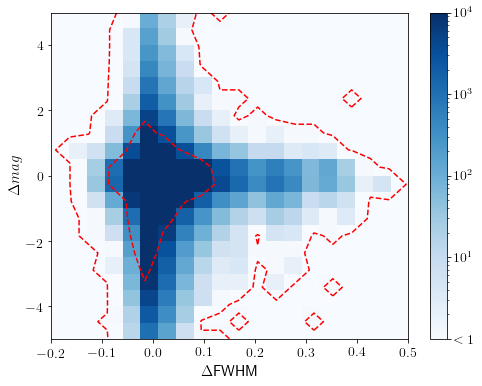

In [170]:
plt.close()
fig=plt.figure(figsize=(8,6))
norm    =   matplotlib.colors.LogNorm(vmin=1,vmax=1e4)
cmap    =   plt.cm.Blues
ax=fig.add_subplot(1,1,1)
ax.imshow(hist2D2[0].T+1e-1,cmap=cmap,norm=norm,\
    origin='lower',extent=(-0.2,0.5,-5,5),aspect='auto')
ax.contour(hist2D2[0].T,levels=[5e-1,1e4],colors=['red']*2,
        extent=(-0.2,0.5,-5,5),linestyles='dashed')
ax.set_xlabel(r'$\Delta$FWHM',fontsize=15)
ax.set_ylabel(r'$\Delta mag$',fontsize=15)
mappable=   plt.cm.ScalarMappable(cmap=cmap,norm=norm)
mappable.set_array([])
cb=plt.colorbar(mappable)
cb.set_ticks([1,1e1,1e2,1e3,1e4])
cb.set_ticklabels(['$<1$','$10^{1}$','$10^{2}$','$10^{3}$','$10^{4}$'])
fig

In [165]:
mask=hist2D2[0]>0
hist2D2[0][mask].min()

1.0

In [173]:
mask2=(~np.isnan(dfwhm))
dmagU=-data19['dmag'][mask1&mask2]
dfwhmU=dfwhm[mask1&mask2]

In [179]:
dmagU=dmagU-np.average(dmagU)
dfwhmU=dfwhmU-np.average(dfwhmU)

In [180]:
print(np.average(dmagU*dfwhmU)/np.std(dmagU)/np.std(dfwhmU))

-0.008562219
